# Dataset CamVid per DeepLabV3

Questo notebook definisce:
- **`CamVidDataset`** – classe `Dataset` PyTorch per il caricamento di immagini e maschere CamVid
- **`make_loader`** – funzione che costruisce un `DataLoader` con le impostazioni standard
- **`build_dataloaders`** – funzione di alto livello che restituisce i tre loader (train, val, test)

Struttura della cartella `archive/`:
```
archive/
├── train/           # immagini  → 0001TP_009210.png
├── train_labels/    # maschere  → 0001TP_009210_L.png  (suffisso _L)
├── val/
├── val_labels/
├── test/
├── test_labels/
└── class_dict.csv
```

## 1. Import

In [1]:
import os
from pathlib import Path

import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

import conf
from transforms import get_train_transforms, get_val_transforms
from utils import encode_mask

## 2. Classe `CamVidDataset`

In [2]:
class CamVidDataset(Dataset):
    """Dataset PyTorch per CamVid.

    Parametri
    ----------
    images : list[Path]
        Percorsi delle immagini RGB.
    masks : list[Path]
        Percorsi delle maschere RGB (stessa lunghezza di `images`).
    transforms : A.Compose | None
        Pipeline albumentations applicata a immagine e maschera insieme.
        Se None, viene restituito il tensore grezzo normalizzato in [0, 1].
    """

    def __init__(self, images: list[Path], masks: list[Path], transforms=None):
        super().__init__()
        assert len(images) == len(masks), "Il numero di immagini e maschere deve coincidere."
        self.images = images
        self.masks = masks
        self.transforms = transforms

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        """Restituisce (immagine, maschera) come tensori PyTorch.

        - immagine : [3, H, W]  float32, normalizzata con media/std ImageNet
        - maschera : [H, W]     int64,   valori in [0, N_CLASSES-1] o IGNORE_INDEX
        """
        img  = np.array(Image.open(self.images[index]).convert("RGB"))
        mask = encode_mask(np.array(Image.open(self.masks[index]).convert("RGB")))

        if self.transforms is not None:
            out = self.transforms(image=img, mask=mask)
            return out["image"], out["mask"].long()

        # Fallback senza trasformazioni
        img_tensor  = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
        mask_tensor = torch.from_numpy(mask).long()
        return img_tensor, mask_tensor

## 3. Raccolta dei percorsi per split

In CamVid ogni maschera ha lo stesso nome dell'immagine con il suffisso `_L` aggiunto prima dell'estensione  
(es. `0001TP_009210.png` → `0001TP_009210_L.png`).

In [3]:
def collect_split(img_dir: Path, mask_dir: Path) -> tuple[list[Path], list[Path]]:
    """Legge tutti i file PNG in `img_dir` e individua la maschera corrispondente in `mask_dir`.

    La maschera si ottiene aggiungendo il suffisso `_L` al nome dell'immagine:
        0001TP_009210.png  →  0001TP_009210_L.png
    """
    images = sorted(img_dir.glob("*.png"))
    masks  = [mask_dir / (img.stem + "_L.png") for img in images]

    missing = [m for m in masks if not m.exists()]
    assert not missing, f"Maschere mancanti in {mask_dir}: {missing}"

    return images, masks

## 4. `make_loader`

In [4]:
def make_loader(dataset: Dataset, batch_size: int, shuffle: bool) -> DataLoader:
    """Costruisce un DataLoader con impostazioni ottimizzate.

    - `drop_last=True` solo in training per evitare batch di dimensione 1.
    - `persistent_workers=True` se num_workers > 0 (riduce l'overhead di spawn).
    """
    num_workers = min(4, os.cpu_count() or 1)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=shuffle,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=num_workers > 0,
        generator=torch.Generator().manual_seed(conf.SEED),
    )

## 5. `build_dataloaders`

In [19]:
def build_dataloaders(
    root: Path = conf.DATA_ROOT,
    batch_size: int = conf.BATCH_SIZE,
    height: int = conf.IMG_HEIGHT,
    width: int = conf.IMG_WIDTH,
    augment: bool = False,
) -> tuple[DataLoader, DataLoader, DataLoader]:
    """Restituisce i DataLoader di train, val e test.

    Parametri
    ----------
    root : Path
        Cartella radice del dataset CamVid (di default `archive/`).
    batch_size : int
        Dimensione del batch.
    height, width : int
        Dimensioni a cui ridimensionare ogni immagine.
    augment : bool
        Se True, applica data augmentation al training
        (zoom casuale, crop casuale, flip orizzontale, color jitter).
    """
    # --- raccolta percorsi ---
    train_imgs, train_masks = collect_split(root / "train",  root / "train_labels")
    val_imgs,   val_masks   = collect_split(root / "val",    root / "val_labels")
    test_imgs,  test_masks  = collect_split(root / "test",   root / "test_labels")

    # --- trasformazioni ---
    if augment:
        train_tf = get_train_transforms(
            height=height, width=width,
            crop_size=(height, width),
            hflip=True,
            scale_range=conf.SCALE_RANGE,
            color_jitter=True,
        )
    else:
        train_tf = get_train_transforms(height=height, width=width)

    val_tf = get_val_transforms(height=height, width=width)

    # --- dataset ---
    train_ds = CamVidDataset(train_imgs, train_masks, transforms=train_tf)
    val_ds   = CamVidDataset(val_imgs,   val_masks,   transforms=val_tf)
    test_ds  = CamVidDataset(test_imgs,  test_masks,  transforms=val_tf)

    # --- loader ---
    train_loader = make_loader(train_ds, batch_size, shuffle=True)
    val_loader   = make_loader(val_ds,   batch_size, shuffle=False)
    test_loader  = make_loader(test_ds,  batch_size, shuffle=False)

    return train_loader, val_loader, test_loader

## 6. Visualizzazione campione casuale

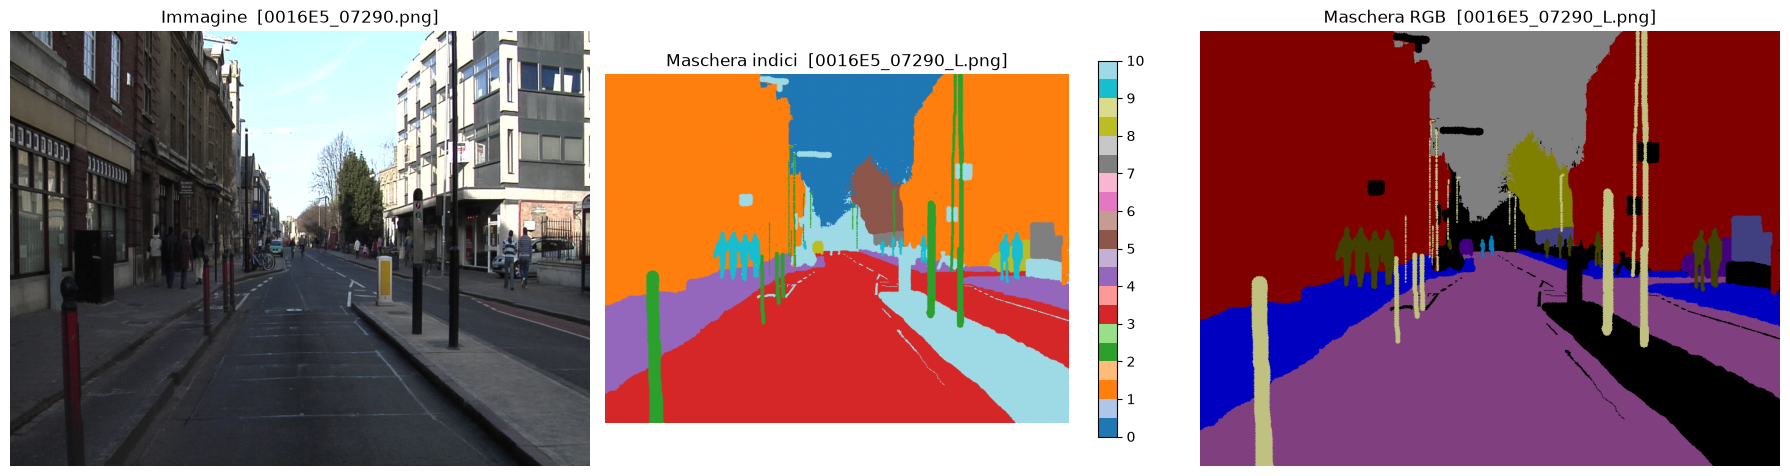

In [17]:
import random
import matplotlib.pyplot as plt
from utils import decode_segmap

# Campiona un'immagine casuale dallo split di train
train_imgs, train_masks = collect_split(conf.DATA_ROOT / "train", conf.DATA_ROOT / "train_labels")
idx = random.randrange(len(train_imgs))

img      = np.array(Image.open(train_imgs[idx]).convert("RGB"))
mask     = encode_mask(np.array(Image.open(train_masks[idx]).convert("RGB")))
mask_rgb = decode_segmap(mask)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(img)
axes[0].set_title(f"Immagine  [{train_imgs[idx].name}]")
axes[0].axis("off")

im = axes[1].imshow(mask, cmap="tab20", vmin=0, vmax=conf.N_CLASSES - 1)
axes[1].set_title(f"Maschera indici  [{train_masks[idx].name}]")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], ticks=range(conf.N_CLASSES), shrink=0.8)

axes[2].imshow(mask_rgb)
axes[2].set_title(f"Maschera RGB  [{train_masks[idx].name}]")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 7. Verifica rapida

In [ ]:
train_loader, val_loader, test_loader = build_dataloaders(augment=True)

print(f"Train batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")
print(f"Test  batches : {len(test_loader)}")

imgs, masks = next(iter(train_loader))
print(f"\nBatch immagini : {imgs.shape}   dtype={imgs.dtype}")
print(f"Batch maschere : {masks.shape}  dtype={masks.dtype}")
print(f"Classi uniche nel batch: {masks.unique().tolist()}")